In [1]:
import base
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import numpy as np
import matplotlib.pyplot as plt
#from tqdm import tqdm_notebook as tqdm
from tqdm.auto import tqdm
import torch
import time

#from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import lqproblem
import optimiser_lqproblem as optimiser_lqproblem
from math import factorial
import pickle

C:\Users\User\anaconda3\Lib\site-packages\torch\__init__.py:1275: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\tensor\python_tensor.cpp:436.)
  _C._set_default_tensor_type(t)


In [2]:
# b0 = 1
# b1 = 1
# b2 = 1
# sigma0 = 1
# sigma2 = 1

# params = {'b0': b0, 'b1': b1, 'b2': b2,
#           'sigma0': sigma0, 'sigma2': sigma2, 'X0': 10, 
#           'A': 0, 'B': 1, 'C': 0, 'D':0, 'E':1, 'G': 0,
#           'T': 1, 'Nt': 1_000}

# with open(f'experiment_params.pkl', 'wb') as f:
#     pickle.dump(params, f)
#     f.close()

In [3]:
with open(f'experiment_params.pkl', 'rb') as f:
    params = pickle.load(f)
    f.close()

params['Nt'] = 1_000

env = lqproblem.environment(**params)
env_hjb = lqproblem.environment(**params)
env_hjb_sig = lqproblem.environment(**params)

Simulating HJB control
Time elapsed: 7.91715935 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

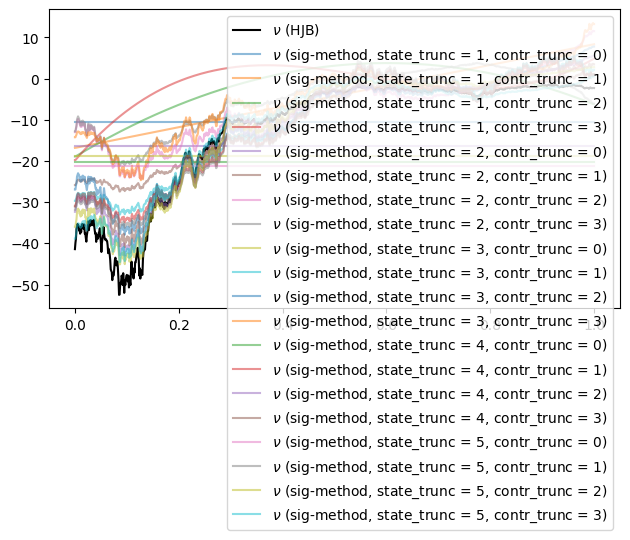

In [4]:
max_order_x_list = [1, 2, 3, 4, 5]
max_order_F_list = [0, 1, 2, 3]
max_max_order_F = max(max_order_F_list)
sim_list = []
dim = env.dim # equals 2
nsims = 10
nsims_small = nsims
random_seed = 123
nsim = 0  # choose one sample path

# simulate with actual optimal control from HJB
print('Simulating HJB control')
start = time.process_time()
np.random.seed(random_seed)
env_hjb.simulate(nsims, lqproblem.strategy_hjb_feedback, order = 1, fast = True)  # order doesn't matter for HJB control
print(f'Time elapsed: {time.process_time() - start} seconds')
hjb_performance = env_hjb.performance.mean()
plt.plot(env.timesteps, env_hjb.nu[:,nsim], label=r'$\nu$ (HJB)', color='black')

with tqdm(total=len(max_order_x_list)*len(max_order_F_list)) as pbar:
    for max_order_x in max_order_x_list:
        for max_order_F in max_order_F_list:
            # if max_order_x == 2 and max_order_F < 2:
            #     pbar.update(1)
            #     continue
            max_order_fn = max(2*max_order_x + 1, 2*max_order_F + 1)
            filename = f'lev_control_{max_order_F}_lev_state_{max_order_x}_analytical'
            max_order_F
            with open(f'F_optimised_lqproblem_{filename}.pkl', 'rb') as f:
                F = pickle.load(f)
                f.close()
            F = ta.sig_to_tensor(F, env.dim, max_order_F)
            strag_sig = lqproblem.sig_strag_dot(F, order = max_order_F)
            # simulation with signature controls
            np.random.seed(random_seed)
            env.simulate(nsims, strag_sig, max_max_order_F, fast = False)
            #if max_order_x >= 4 and max_order_F >= 2:
                #plt.plot(env.timesteps, env.nu[:,nsim], label=rf'$\nu$ (sig-method, state_trunc = {max_order_x}, contr_trunc = {max_order_F})',
                    #alpha=0.5)
            plt.plot(env.timesteps, env.nu[:,nsim], label=rf'$\nu$ (sig-method, state_trunc = {max_order_x}, contr_trunc = {max_order_F})',
                    alpha=0.5)
            nu_rmse_list = np.sqrt((((env.nu - env_hjb.nu)**2).sum(axis=0))*env.T/env.Nt)
            mean_performance = env.performance.mean()
            sim_inst = {'max_order_x': max_order_x, 
                        'max_order_F': max_order_F, 
                        'nu_sims': env.nu[:,:nsims_small],
                        'performance_list': env.performance[:nsims_small],
                        'performance_mean': mean_performance,
                        'outperformance': mean_performance - hjb_performance,
                        'nu_L2_dist_list': nu_rmse_list[:nsims_small],
                        'nu_L2_dist_mean': nu_rmse_list.mean()}
            sim_list.append(sim_inst)
            pbar.update(1)
        
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
with open(f'experiment_results_{nsims}_sims.pkl', 'wb') as f:
    pickle.dump(sim_list, f)
    f.close()

sim_hjb = {'nu_sims': env_hjb.nu[:,:nsims_small],
           'performance_list': env_hjb.performance[:nsims_small],
           'performance_mean': env_hjb.performance.mean()}

with open(f'experiment_results_hjb_{nsims}_sims.pkl', 'wb') as f:
    pickle.dump(sim_hjb, f)
    f.close()

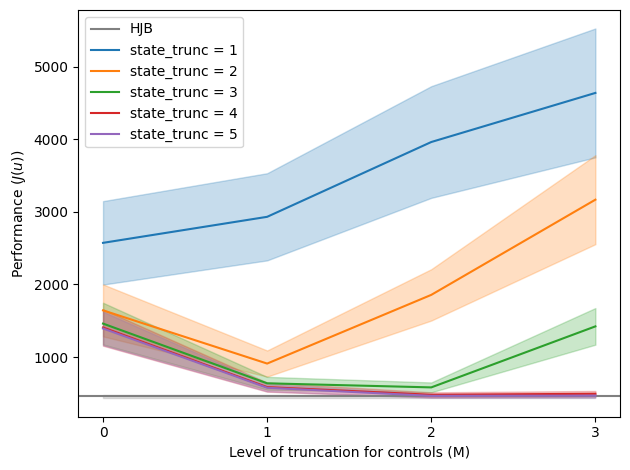

In [6]:
Z_val = 1.96

perform_hjb = sim_hjb['performance_mean']
perform_hjb_list = sim_hjb['performance_list']
perform_hjb_std = perform_hjb_list.std(ddof = 1)/np.sqrt(nsims)
perform_hjb_LCI = perform_hjb - Z_val*perform_hjb_std
perform_hjb_UCI = perform_hjb + Z_val*perform_hjb_std
plt.fill_between(max_order_F_list, perform_hjb_LCI, perform_hjb_UCI,alpha=0.25, color='grey')
plt.axhline(perform_hjb, color = 'grey', label='HJB')

for n, max_order_x in enumerate(max_order_x_list):
    perform = [experiment['performance_mean'] for experiment in sim_list if experiment['max_order_x']==max_order_x]
    perform_list = np.array([experiment['performance_list'] for experiment in sim_list if experiment['max_order_x']==max_order_x])
    perform_std = perform_list.std(axis = 1, ddof = 1)/np.sqrt(nsims)
    perform_LCI = perform - Z_val*perform_std
    perform_UCI = perform + Z_val*perform_std
    plt.fill_between(max_order_F_list, perform_LCI, perform_UCI,alpha=0.25, color=f'C{n}')
    plt.plot(max_order_F_list, perform, label=f'state_trunc = {max_order_x}', color=f'C{n}')

plt.xticks(ticks=max_order_F_list)
plt.xlabel(r'Level of truncation for controls (M)')
plt.ylabel(r'Performance ($J(u)$)')
plt.legend()
plt.tight_layout()
plt.show()
        

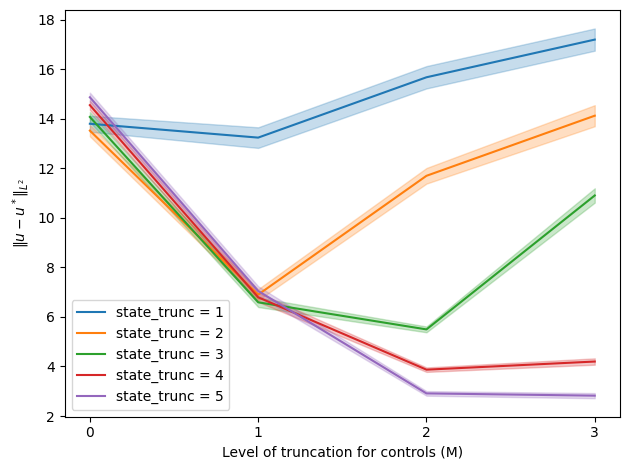

In [7]:
# for max_order_x in max_order_x_list:
#     perform_diff = [experiment['nu_rmse'] for experiment in sim_list if experiment['max_order_x']==max_order_x]
#     plt.plot(max_order_F_list, perform_diff, label=f'state_trunc = {max_order_x}')

for n, max_order_x in enumerate(max_order_x_list):
    nu_L2_dist = [experiment['nu_L2_dist_mean'] for experiment in sim_list if experiment['max_order_x']==max_order_x]
    nu_L2_dist_list = np.array([experiment['nu_L2_dist_list'] for experiment in sim_list if experiment['max_order_x']==max_order_x])
    nu_L2_dist_std = nu_L2_dist_list.std(axis = 1, ddof = 1)/np.sqrt(nsims)
    nu_L2_dist_LCI = nu_L2_dist - Z_val*nu_L2_dist_std
    nu_L2_dist_UCI = nu_L2_dist + Z_val*nu_L2_dist_std
    plt.fill_between(max_order_F_list, nu_L2_dist_LCI, nu_L2_dist_UCI,alpha=0.25, color=f'C{n}')
    plt.plot(max_order_F_list, nu_L2_dist, label=f'state_trunc = {max_order_x}', color=f'C{n}')

plt.xticks(ticks=max_order_F_list)
plt.xlabel(r'Level of truncation for controls (M)')
plt.ylabel(r'$\|u - u^*\|_{L^2}$')
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
sim_list

[{'max_order_x': 1,
  'max_order_F': 0,
  'nu_sims': array([[-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         ...,
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5]],
        shape=(1001, 1000)),
  'performance_list': array([1.29718356e+02, 1.11224070e+02, 5.91680288e+03, 1.15322777e+02,
         1.95785154e+02, 1.17946668e+02, 1.10432608e+02, 9.10382504e+03,
         2.08755010e+02, 1.14801872e+02, 6.70945580e+03, 1.23652785e+02,
         6.03844902e+02, 2.84553345e+02, 2.18700967e+04, 1.22874902e+02,
         1.10412404e+02, 1.75223477e+02, 1.38144903e+02, 1.37990753e+03,
         1.24944460e+03, 4.99452747e+02, 1.10566832e+02, 1.12465677e+02,
         1.31883181e+02, 1.38166597e+02, 2.40870305e+02, 1.12521626e+02,
         3.69479390e+02, 4